# Clean POD–PINN results

This notebook summarizes the clean rebuild from 48 source CFD arrays. No old checkpoint or derived model artifact was reused.

## Locked study design

- Native-mesh, cell-volume-weighted rank-25 POD
- Delaunay structured grid only for physics derivatives and visualization
- Two hidden layers: 32×32, 64×64, 128×128
- tanh, L-BFGS only, L2=1e-4
- data/continuity/momentum/boundary multipliers = 1/1/1/1

In [1]:
# Precomputed held-out validation summary
print(comparison_table)

width   u[%]    w[%]    p[%]  nut[%]  mean[%]
 32   0.138   4.803   4.269   2.220    2.858
 64   0.111   2.087   2.002   1.505    1.426
128   0.105   2.919   2.852   1.586    1.865


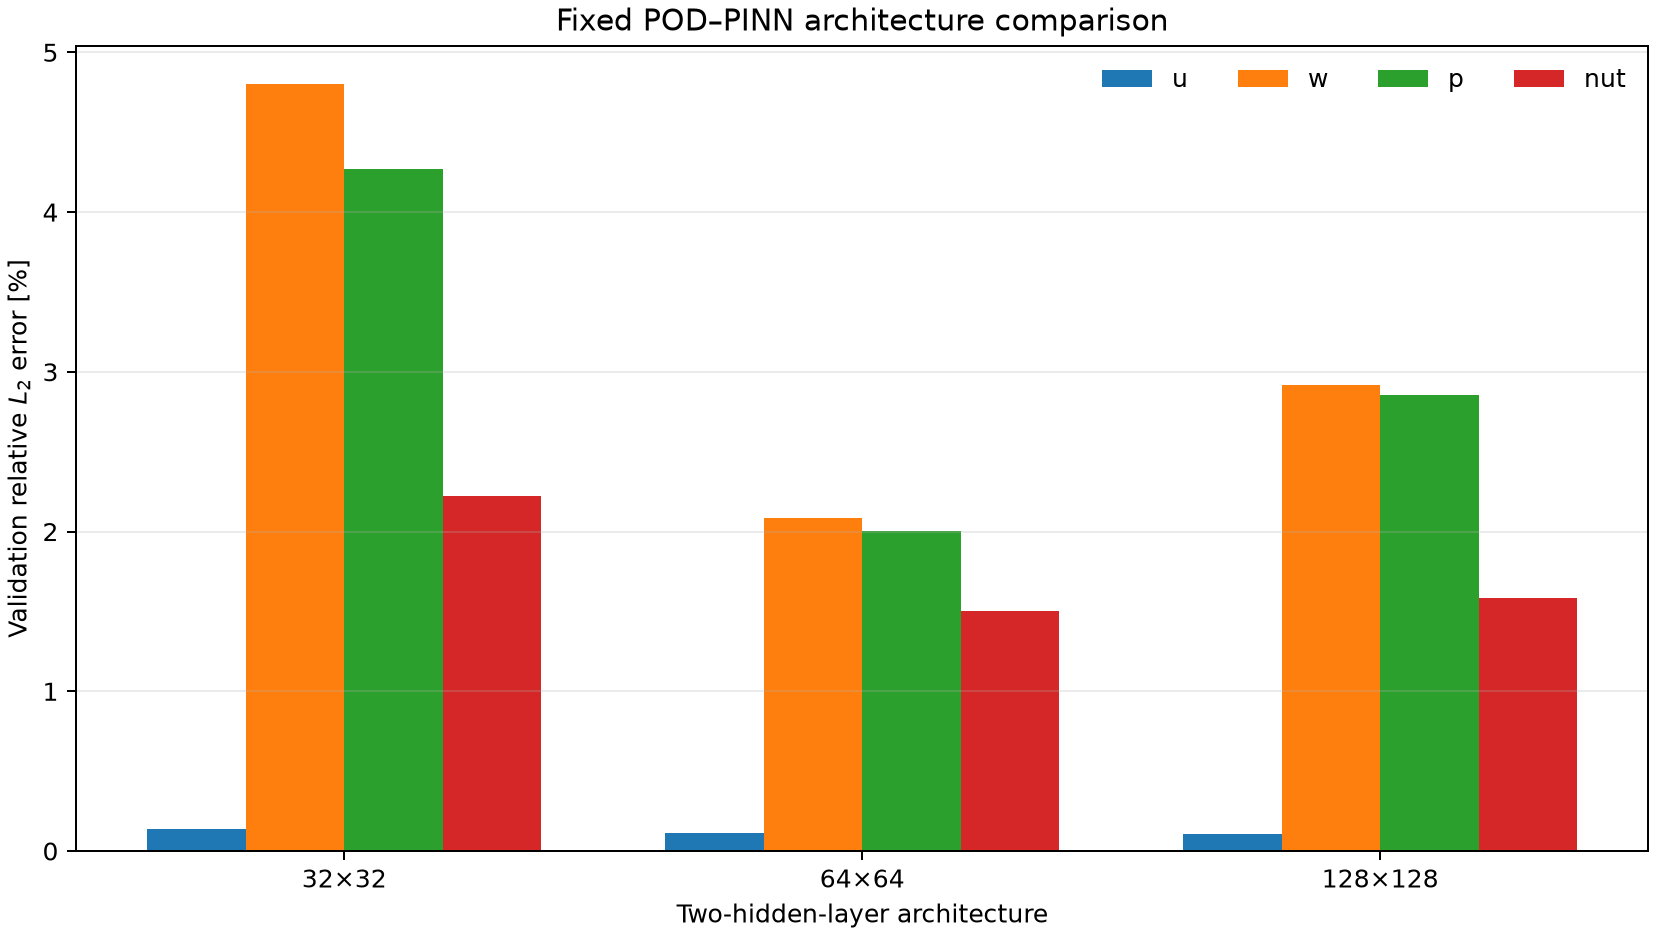

In [2]:
# Architecture comparison generated by make_results.py
from IPython.display import Image, display
display(Image('artifacts/results/figures/architecture_comparison.png'))

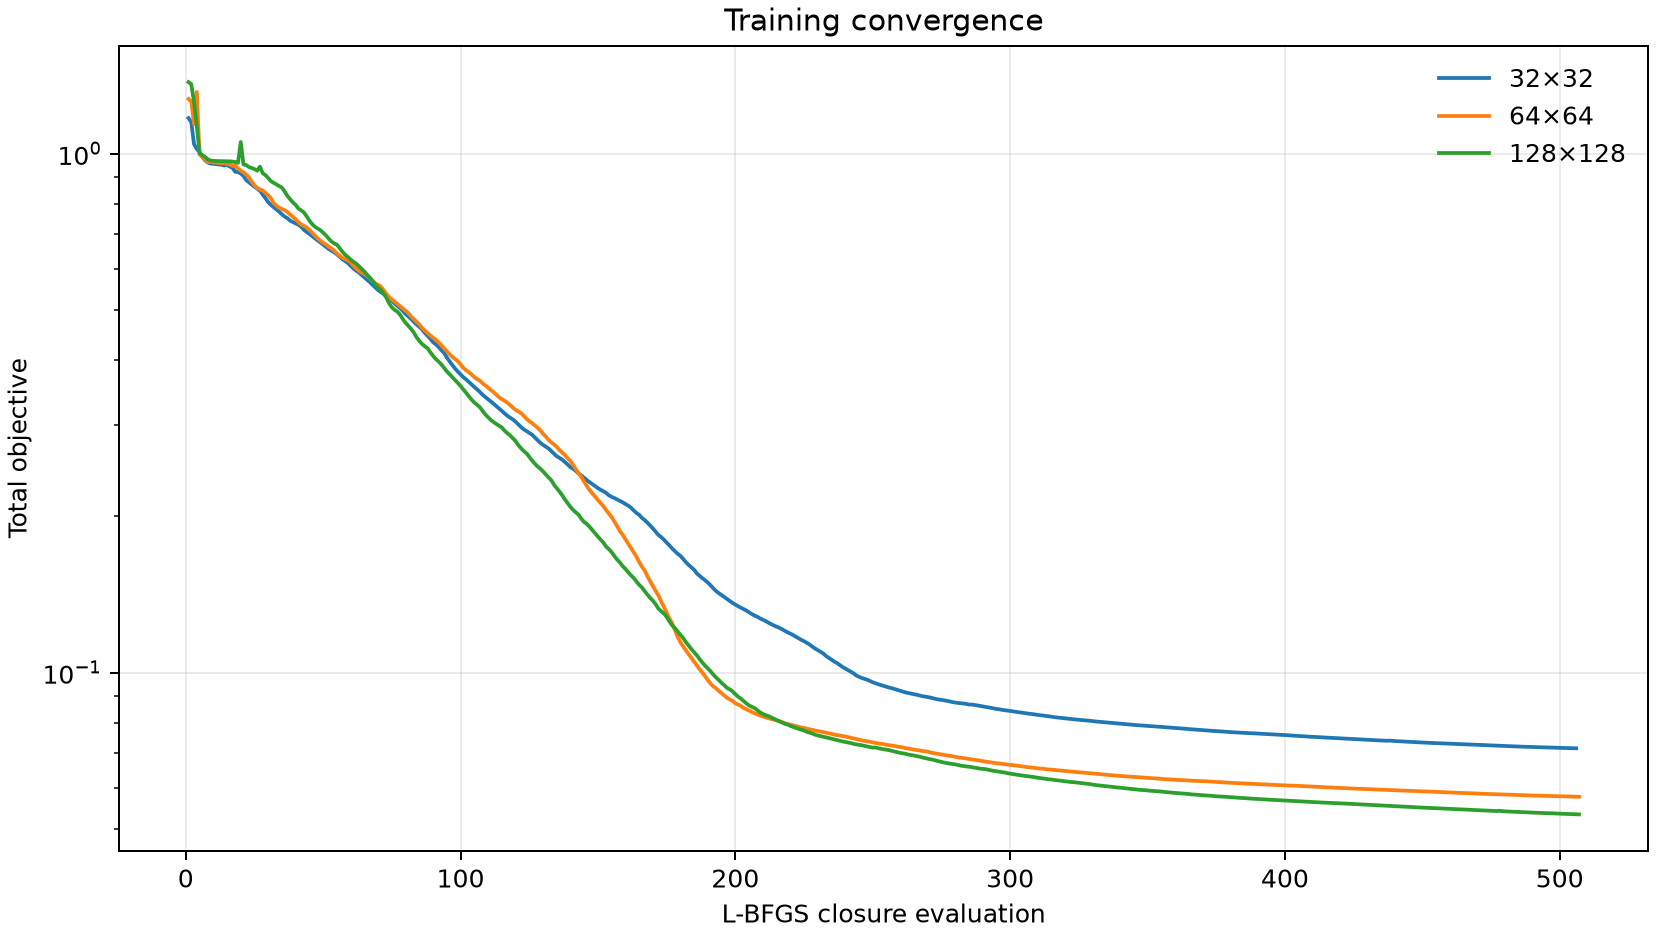

In [3]:
# L-BFGS convergence
display(Image('artifacts/results/figures/training_convergence.png'))

## Delaunay/operator validation

In [4]:
# Precomputed manufactured-solution and CFD residual checks
print(operator_checks)

Manufactured derivative relative RMS errors:
  dx: 8.818e-05
  dz: 1.569e-05
  dxx: 1.511e-04
  dzz: 2.360e-05
  dxz: 8.554e-05

Maximum normalized CFD-grid residual imbalance:
  continuity_normalized: 6.156%
  momentum_x_normalized: 5.517%
  momentum_z_normalized: 3.025%


The analytic derivative check passes comfortably. Reference-CFD residuals set a finite-difference/interpolation floor, so physics loss should not be interpreted as exact near-wall PDE enforcement.

## Best model: 64×64

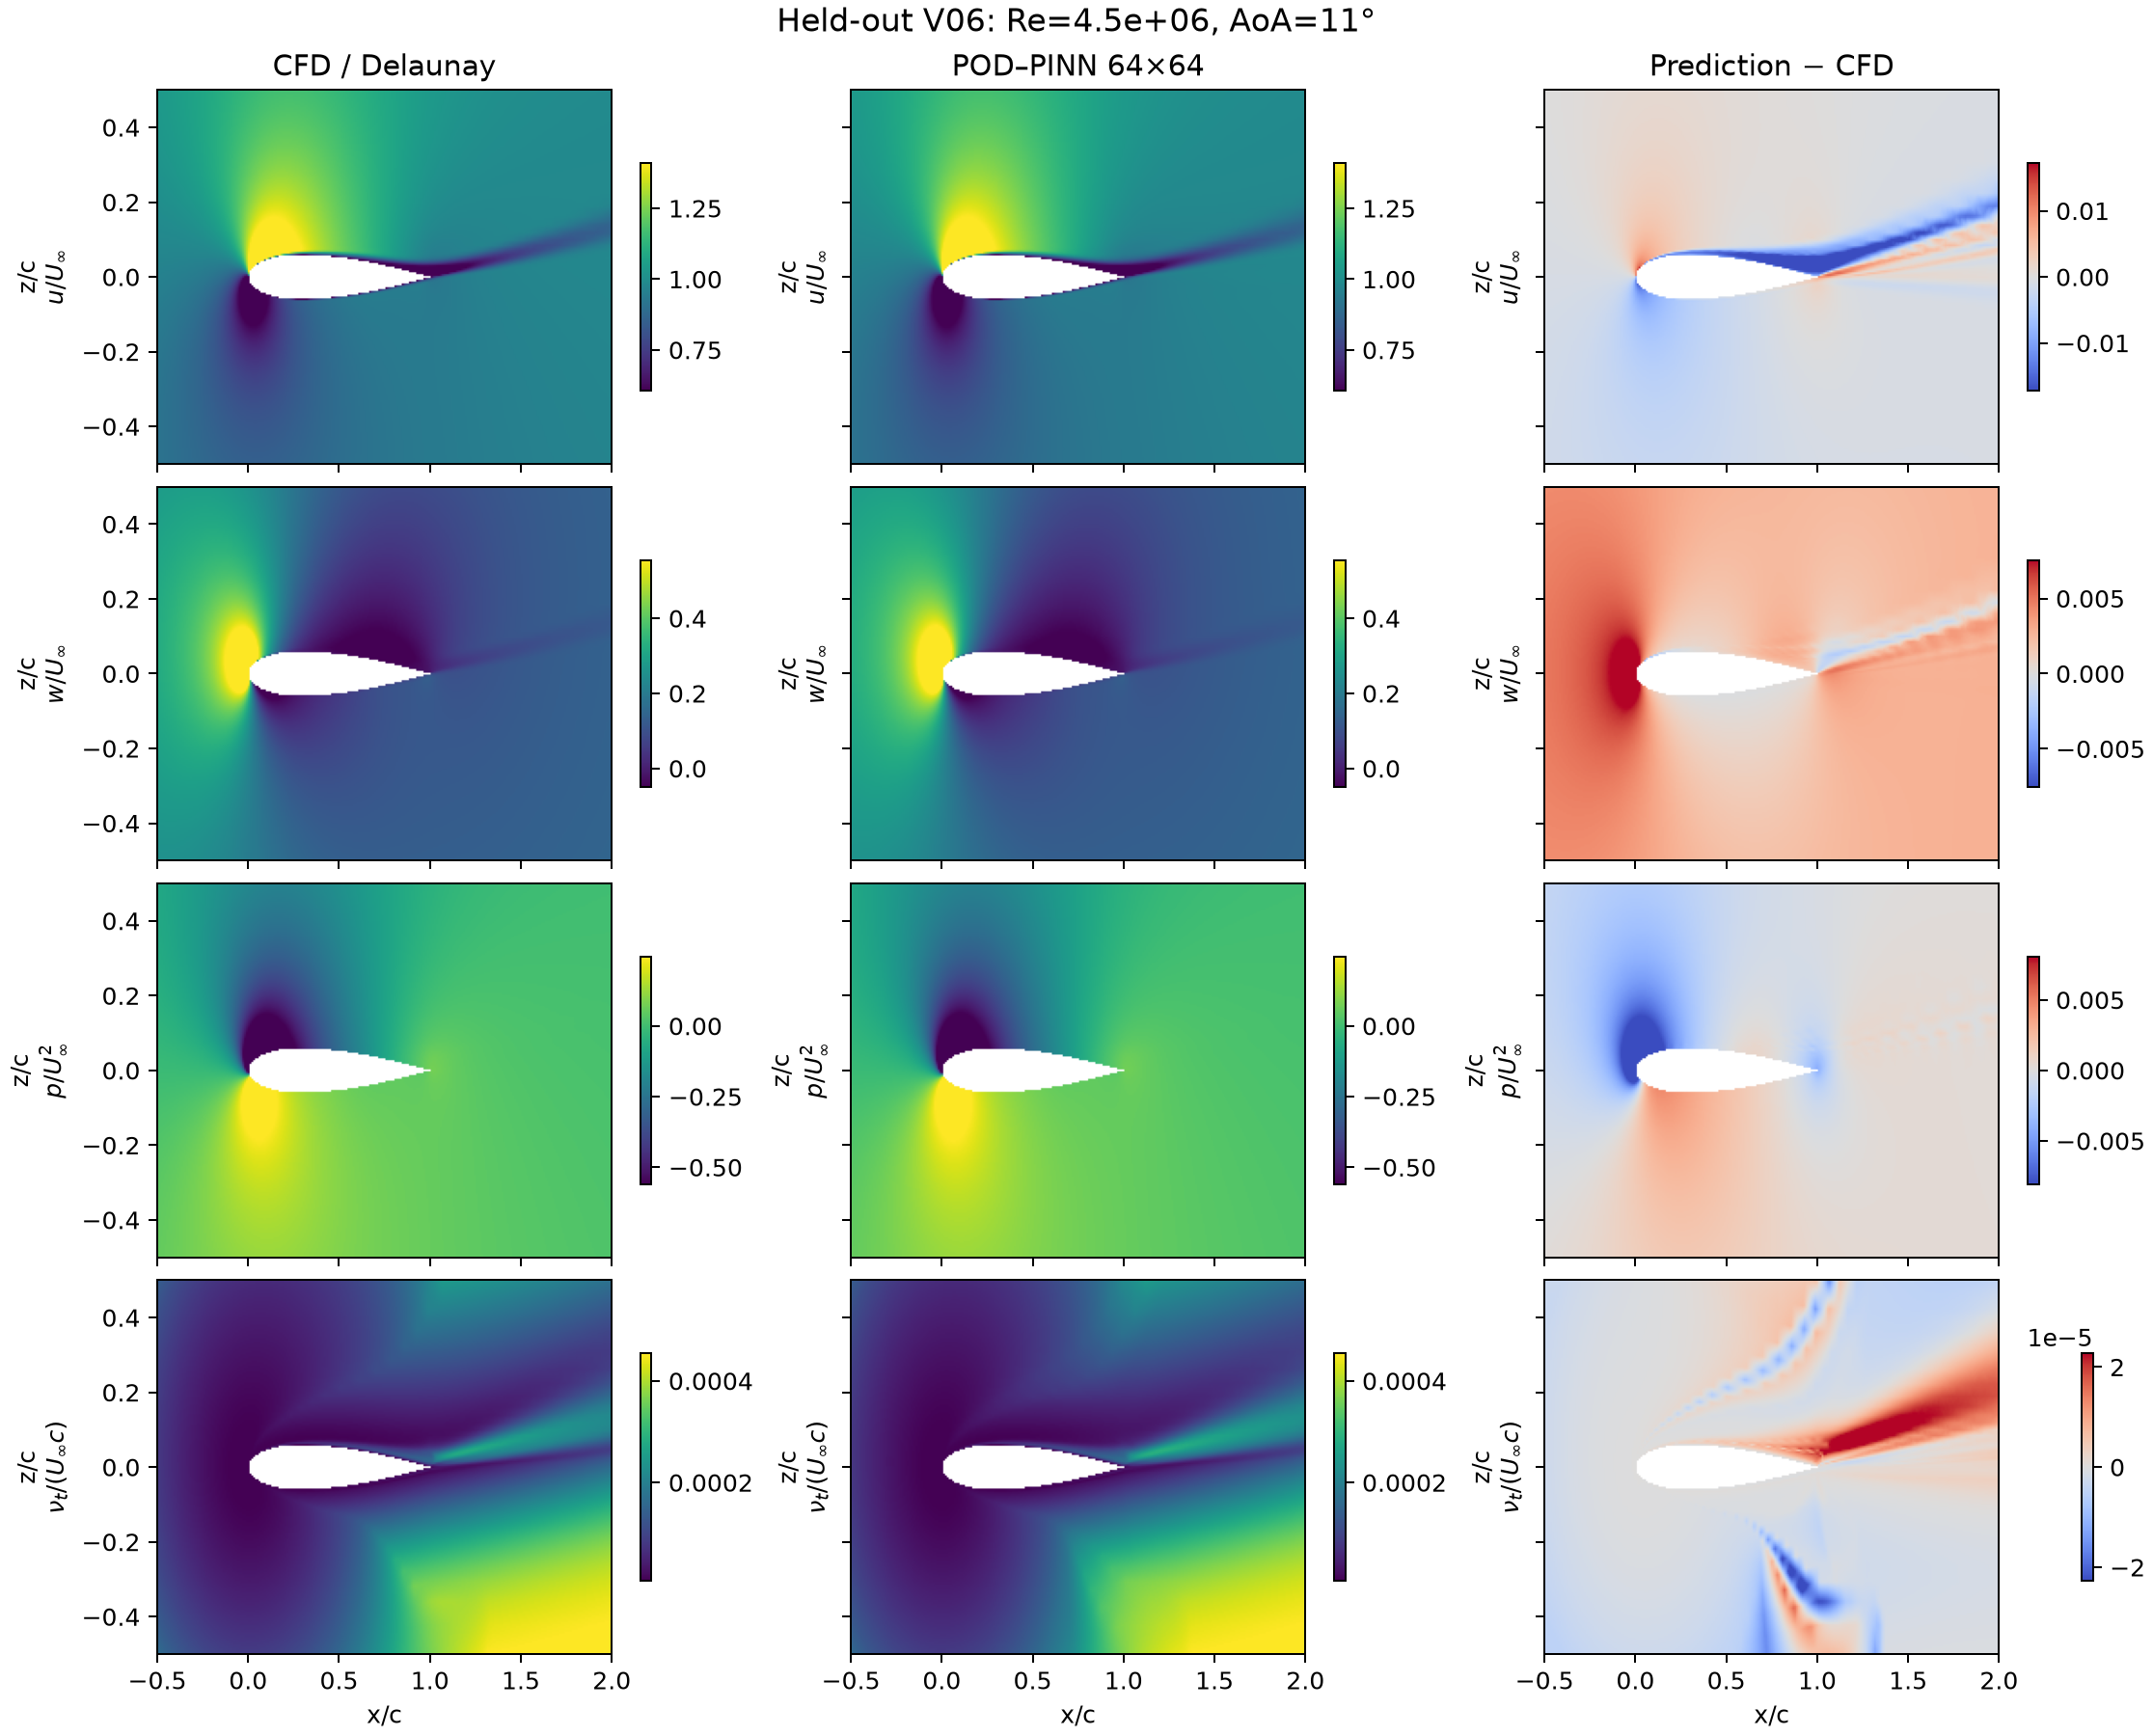

In [5]:
# Representative held-out case (V06: Re=4.5e6, AoA=11 deg)
display(Image('artifacts/results/figures/best_model_heldout_contours.png'))

## Conclusion

The 64×64 model gives the lowest mean validation field error (1.426%). The 128×128 network fits training slightly better but generalizes worse for cross-flow velocity and pressure. Use `artifacts/models/pod_pinn_2x64_rank25.pt`.

Limitations: the wall-adjacent 0.02c band is excluded from the structured physics operator; force metrics are pressure-only; and only 10/48 source cases pass the conservative force-tail stability flag.